# Supp Fig 2: colocalisation distance optimisation

For each sample (LM39 cell, LM39 liver, LM50GS mouse brain) and each MERFISH gene, plot the % of MERFISH callouts colocalised with each Guidestar gene as a function of the colocalisation distance (panel c), and the grouped values at the selected distance (panel d).

All input CSVs are read from this folder (`DataForFigures`).

In [ ]:
import os

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# SVG output: keep text as real (editable) text, Arial-like sans-serif font
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

DATA_DIR = '../DataForFigures'         # input CSVs, relative to this notebook (Figures/)
OUTPUT_DIR = os.path.join(DATA_DIR, 'results')         # set to a folder path to save the SVGs
SELECTED_DISTANCE = 4.0   # px, distance used for all downstream colocalisation

DATASETS = [
    dict(name='cell',
         title='AML-12 cell line sample',          # figure title
         sample_name='LM39 cell culture sample (25 FOVs)',
         distopt='Cell_LM39_25FOVs_distopt_results.csv',
         counts='Cell_LM39_25FOVs_Colocalisation_counts.csv',
         genes=['Acly', 'Gpam', 'Hnf4a', 'Ube2z']),
    dict(name='liver',
         title='Liver tissue sample',
         sample_name='LM39 liver tissue sample (49 FOVs)',
         distopt='Liver_LM39_49FOVs_distopt_results.csv',
         counts='Liver_LM39_49FOVs_Colocalisation_counts.csv',
         genes=['Acly', 'Gpam', 'Hnf4a', 'Pigr']),
    dict(name='brain',
         title='Brain tissue sample',
         sample_name='Mouse brain tissue sample (86 FOVs)',
         distopt='mBrain_LM50GS_86FOVs_distopt_results.csv',
         counts='Tissue_LM50GS_86FOVs_Colocalisation_counts_set1.csv',
         genes=['Slc1a2', 'Cacna1i', 'Cacna1a']),
]

In [15]:
def merfish_totals(counts_df, genes):
    """Total MERFISH callouts per gene (colocalised '1' + not colocalised '0')."""
    merfish = counts_df[counts_df['type'] == 'Merfish'].set_index('gene')
    missing = [g for g in genes if g not in merfish.index]
    if missing:
        raise ValueError(f'No MERFISH totals for {missing}')
    return (merfish.loc[genes, '1'] + merfish.loc[genes, '0']).to_dict()


def load_distopt_pct(ds):
    dist = pd.read_csv(os.path.join(DATA_DIR, ds['distopt']), index_col=0)
    counts = pd.read_csv(os.path.join(DATA_DIR, ds['counts']), index_col=0)
    totals = merfish_totals(counts, ds['genes'])
    dist = dist[dist['merfish gene'].isin(ds['genes'])].copy()
    dist['pct'] = dist['colocalisation counts'] / dist['merfish gene'].map(totals) * 100
    return dist


def guidestar_colocal_pct(ds):
    """% of Guidestar spots colocalised, from the final (4 px) colocalisation run."""
    counts = pd.read_csv(os.path.join(DATA_DIR, ds['counts']), index_col=0)
    gs = (counts[counts['type'] == 'Guidestar']
          .set_index('gene').reindex(ds['genes']))
    return (gs['1'] / (gs['1'] + gs['0']) * 100).rename('pct')


def nice_ylim(max_val, n_ticks=5):
    """Rounded axis top and tick spacing for a percentage axis (capped at 100)."""
    raw_step = max(max_val, 1) / n_ticks
    step = next(s for s in (1, 2, 5, 10, 20, 25) if s >= raw_step)
    top = min(100, step * np.ceil(max_val * 1.05 / step))
    return top, step


def plot_distance_optimisation(ds, dist):
    genes = ds['genes']
    n = len(genes)
    colors = dict(zip(genes, plt.rcParams['axes.prop_cycle'].by_key()['color']))

    at_selected = dist[np.isclose(dist['colocal distance'], SELECTED_DISTANCE)]
    if at_selected.empty:
        raise ValueError(f"{ds['name']}: distance {SELECTED_DISTANCE} not in sweep")
    bar = (at_selected
           .pivot(index='merfish gene', columns='guidestar gene', values='pct')
           .reindex(index=genes, columns=genes))

    ncols = 2
    nrows = int(np.ceil(n / ncols))
    fig = plt.figure(figsize=(13, 2.6 * nrows + 1.0), constrained_layout=True)
    sub_a, sub_b = fig.subfigures(1, 2, width_ratios=[2, 1])

    # ---- panel a: % colocalised vs distance, one subplot per MERFISH gene ----
    axes = np.atleast_1d(sub_a.subplots(nrows, ncols)).ravel()
    for ax, mg in zip(axes, genes):
        sub = dist[dist['merfish gene'] == mg]
        for gg in genes:
            s = sub[sub['guidestar gene'] == gg].sort_values('colocal distance')
            ax.scatter(s['colocal distance'], s['pct'], s=12,
                       color=colors[gg], label=gg)
        ax.set_title(f'{mg} MERFISH callouts', fontsize=10)
        ax.set_ylim(-3, 100)
        ax.set_yticks(np.arange(0, 101, 20))
        ax.tick_params(labelsize=9)
    for ax in axes[n:]:
        ax.set_visible(False)

    sub_a.suptitle(f"{ds['title']}\nPercentage of MERFISH callouts "
                   f"colocalized with Guidestar spots",
                   fontsize=12, fontweight='bold')
    sub_a.supxlabel('Euclidean distance (pixels)', fontsize=11, fontweight='bold')
    sub_a.supylabel('% colocalized', fontsize=11, fontweight='bold')
    sub_a.text(0.0, 1.0, 'a', transform=sub_a.transSubfigure,
               fontsize=20, fontweight='bold', va='top')

    # ---- panel b: grouped bars at the selected distance, legend underneath ----
    ax, leg_ax = sub_b.subplots(2, 1)
    x = np.arange(n)
    width = 0.8 / n
    for i, gg in enumerate(genes):
        ax.bar(x + (i - (n - 1) / 2) * width, bar[gg], width,
               color=colors[gg], label=gg)

    ax.set_xticks(x)
    for label in ax.set_xticklabels(genes):
        label.set_fontweight('bold')
    ax.set_xlabel('MERFISH gene', fontsize=10)
    top_b, step_b = ds.get('ylim_b') or nice_ylim(np.nanmax(bar.values))
    ax.set_yticks(np.arange(0, top_b + 1e-9, step_b))
    ax.set_ylim(0, top_b)
    ax.tick_params(labelsize=9)
    ax.set_title('Percentage of MERFISH callouts\n'
                 'colocalized with Guidestar spots (%)', fontsize=10)
    sub_b.suptitle(f'At selected distance = {SELECTED_DISTANCE:g}:',
                   fontsize=12, fontweight='bold')
    sub_b.text(0.0, 1.0, 'b', transform=sub_b.transSubfigure,
               fontsize=20, fontweight='bold', va='top')

    leg_ax.axis('off')
    handles, labels = ax.get_legend_handles_labels()
    leg = leg_ax.legend(handles, labels, title='Guidestar gene:', loc='upper left',
                        frameon=False, fontsize=10, title_fontsize=10)
    for text, gg in zip(leg.get_texts(), labels):
        text.set_color(colors[gg])
        text.set_fontweight('bold')

    if OUTPUT_DIR:
        os.makedirs(OUTPUT_DIR, exist_ok=True)
        fig.savefig(os.path.join(OUTPUT_DIR, f"{ds['name']}_distance_optimization.svg"),
                    format='svg', bbox_inches='tight')
    return fig, bar

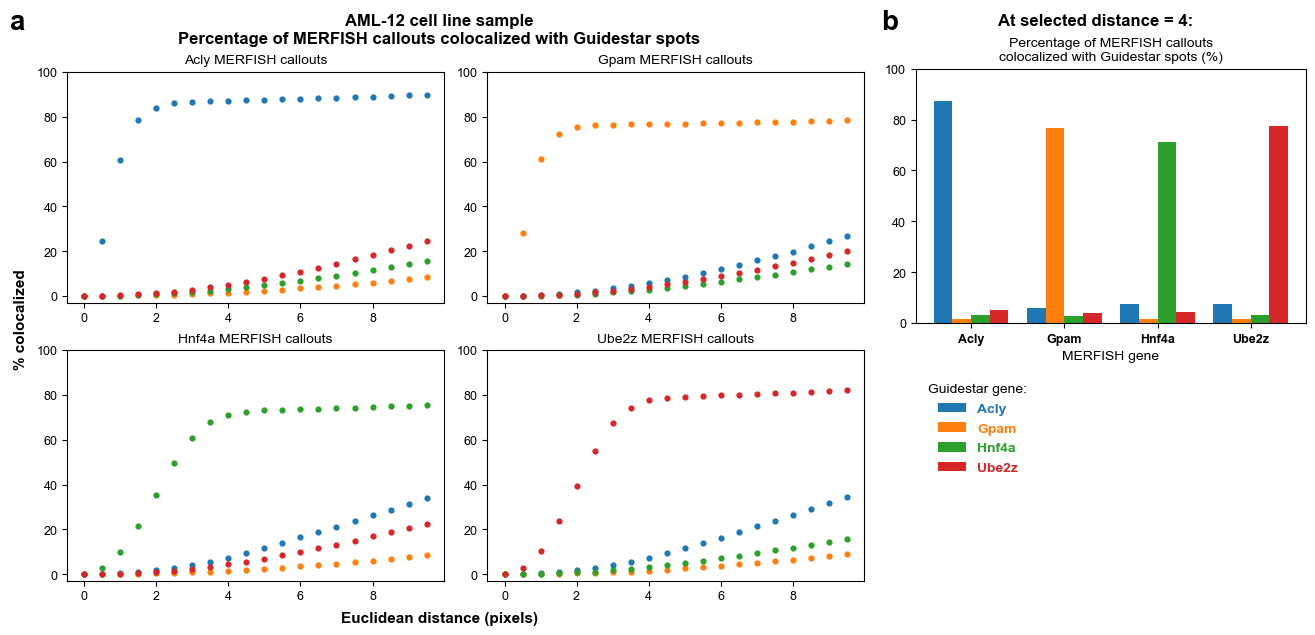

LM39 cell culture sample (25 FOVs): % MERFISH colocalised at 4 px


guidestar gene,Acly,Gpam,Hnf4a,Ube2z
merfish gene,,,,
Acly,87.2,1.5,3.1,5.1
Gpam,5.9,76.7,2.9,4.0
Hnf4a,7.4,1.6,71.1,4.3
Ube2z,7.3,1.6,3.2,77.5


% Guidestar spots colocalised (final 4 px run)


gene
Acly     33.5
Gpam     44.2
Hnf4a    35.1
Ube2z    27.3
Name: pct, dtype: float64

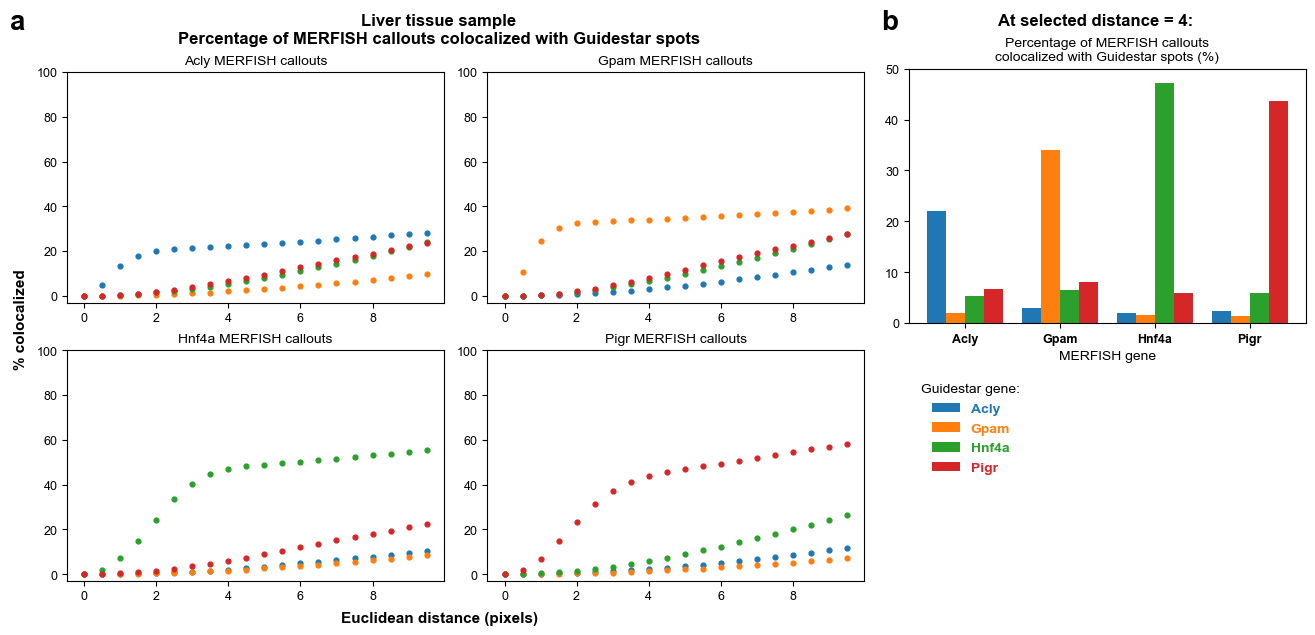

LM39 liver tissue sample (49 FOVs): % MERFISH colocalised at 4 px


guidestar gene,Acly,Gpam,Hnf4a,Pigr
merfish gene,,,,
Acly,22.1,2.0,5.3,6.7
Gpam,2.9,34.1,6.5,8.0
Hnf4a,2.1,1.6,47.1,6.0
Pigr,2.3,1.4,5.9,43.7


% Guidestar spots colocalised (final 4 px run)


gene
Acly      5.2
Gpam     17.7
Hnf4a     6.7
Pigr     21.6
Name: pct, dtype: float64

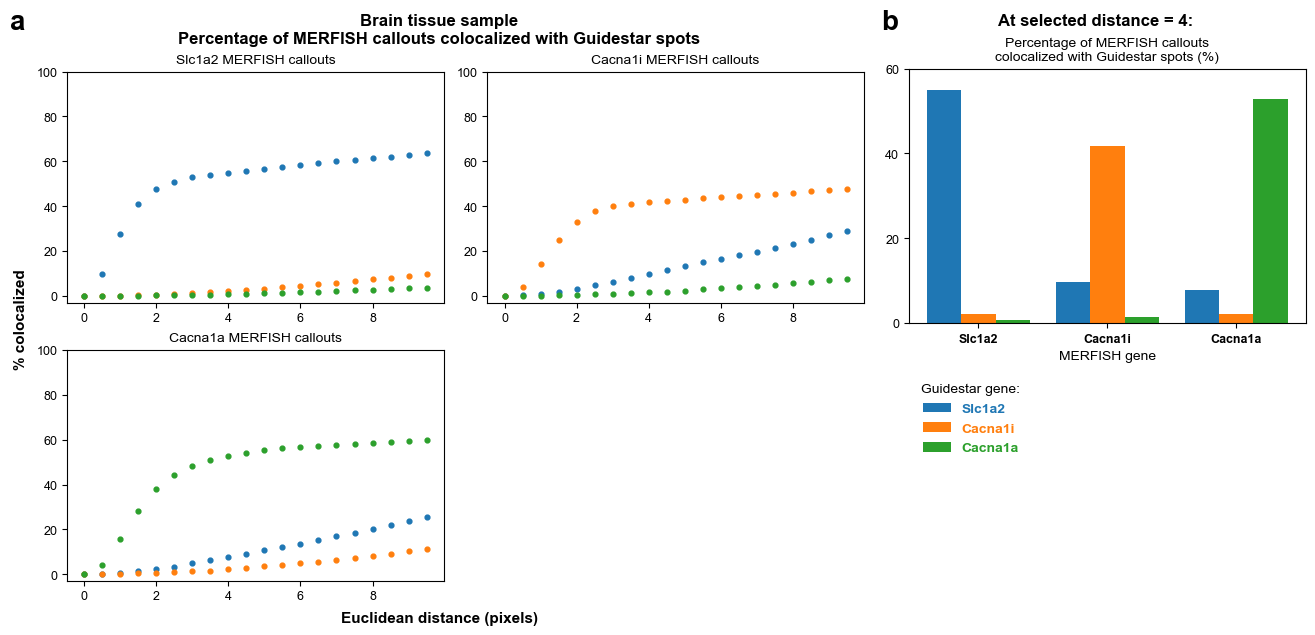

Mouse brain tissue sample (86 FOVs): % MERFISH colocalised at 4 px


guidestar gene,Slc1a2,Cacna1i,Cacna1a
merfish gene,,,
Slc1a2,55.0,2.1,0.7
Cacna1i,9.8,41.8,1.5
Cacna1a,7.7,2.2,52.8


% Guidestar spots colocalised (final 4 px run)


gene
Slc1a2     20.9
Cacna1i     4.0
Cacna1a    32.1
Name: pct, dtype: float64

In [16]:
bar_tables, gs_tables = {}, {}
for ds in DATASETS:
    dist = load_distopt_pct(ds)
    fig, bar = plot_distance_optimisation(ds, dist)
    bar_tables[ds['name']] = bar.round(1)
    gs_tables[ds['name']] = guidestar_colocal_pct(ds).round(1)
    plt.show()
    print(f"{ds['sample_name']}: % MERFISH colocalised at {SELECTED_DISTANCE:g} px")
    display(bar_tables[ds['name']])
    print('% Guidestar spots colocalised (final 4 px run)')
    display(gs_tables[ds['name']])

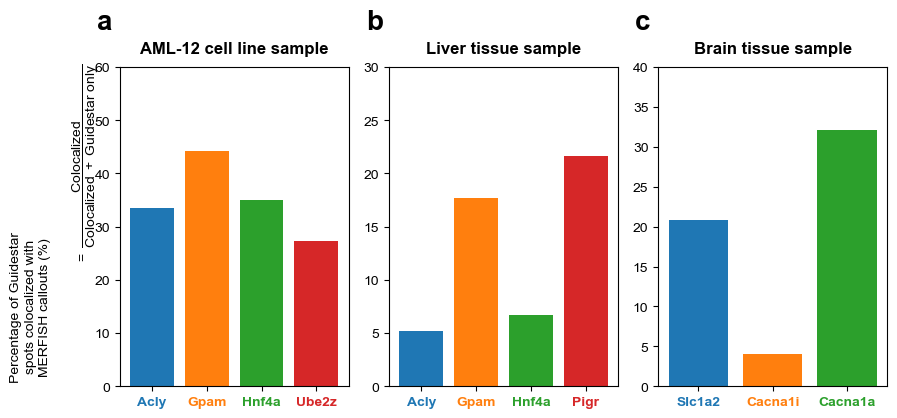

In [33]:
# ---- % of Guidestar spots colocalised with MERFISH callouts, one panel per sample ----
# Colocalized / (Colocalized + Guidestar only), from the Guidestar rows of each
# sample's final (4 px) colocalisation counts.

# Draw the maths (the fraction) in Arial too, so it matches the other text
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Arial'
mpl.rcParams['mathtext.it'] = 'Arial:italic'
mpl.rcParams['mathtext.bf'] = 'Arial:bold'
PANEL_W, PANEL_H = 3.0, 4.3   # inches per panel (width, height)

# (top, tick step) per panel, as in the published figure; samples not listed
# here get an automatic limit from nice_ylim().
GS_YLIM = {'cell': (60, 10), 'liver': (30, 5), 'brain': (40, 5)}

# y-label layout on panel a, in panel-a axes coordinates (x, y);
# tweak these if the two label columns overlap or sit too far out
YLABEL_TEXT_XY = (-0.30, 0.25)   # "Percentage of Guidestar ..." column
YLABEL_FRAC_XY = (-0.15, 0.70)   # "= Colocalized / (...)" column


def plot_guidestar_colocal_pct(datasets):
    colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    fig, axes = plt.subplots(1, len(datasets), figsize=(PANEL_W * len(datasets), PANEL_H))
    axes = np.atleast_1d(axes)

    for ax, letter, ds in zip(axes, 'abcdefgh', datasets):
        pct = guidestar_colocal_pct(ds)
        if pct.isna().any():
            raise ValueError(f"{ds['name']}: no Guidestar counts for "
                             f"{list(pct[pct.isna()].index)}")

        x = np.arange(len(pct))
        ax.bar(x, pct.values, color=colors[:len(pct)])
        ax.set_xticks(x)
        for label, c in zip(ax.set_xticklabels(pct.index), colors):
            label.set_color(c)
            label.set_fontweight('bold')

        top, step = GS_YLIM.get(ds['name']) or nice_ylim(pct.max())
        ax.set_yticks(np.arange(0, top + 1e-9, step))
        ax.set_ylim(0, top)
        ax.tick_params(labelsize=10)
        ax.set_title(ds['title'], fontsize=12, fontweight='bold', pad=10)
        ax.text(-0.1, 1.1, letter, transform=ax.transAxes,
                fontsize=20, fontweight='bold', va='bottom')
    
    # y label on the first panel: text column in the lower half, and the
    # "= fraction" column right next to the tick labels in the upper half
    ax0 = axes[0]
    ax0.set_ylabel('Percentage of Guidestar\nspots colocalized with\nMERFISH callouts (%)',
                   fontsize=10, multialignment='center')
    ax0.yaxis.set_label_coords(*YLABEL_TEXT_XY)
    ax0.text(*YLABEL_FRAC_XY,
             r'$=\ \dfrac{\mathrm{Colocalized}}{\mathrm{Colocalized\ +\ Guidestar\ only}}$',
             transform=ax0.transAxes, rotation=90, fontsize=10,
             ha='center', va='center')

    fig.tight_layout()
    if OUTPUT_DIR:
        os.makedirs(OUTPUT_DIR, exist_ok=True)
        fig.savefig(os.path.join(OUTPUT_DIR, 'guidestar_colocalized_percentage.svg'),
                    format='svg', bbox_inches='tight')
    return fig


fig = plot_guidestar_colocal_pct(DATASETS)
plt.show()